# Part 2 - PCA (variant 1)

In [1]:
import os
import os.path as op
import sys, time
sys.path.append('.')

from paths import *
from tqdm.notebook import trange
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn.plotting import plot_stat_map, show
from sklearn.decomposition import PCA
from nilearn.masking import compute_epi_mask

PCA_DIR = op.join(RESULTS_DIR, "PCA")        
os.makedirs(PCA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

## Load the preprocessed fMRI data

In [2]:
img = nib.load(SMOOTH_PATH + ".nii.gz")
affine = img.affine
data = np.asanyarray(img.dataobj)                 
print(data.shape, data.dtype)

(91, 109, 91, 316) float32


## Preprocessing

In [3]:
vol_shape = data.shape[:3]
n_vols = data.shape[3]
print("volume shape:", vol_shape)
print("number of volumes:", n_vols)

volume shape: (91, 109, 91)
number of volumes: 316


In [4]:
mean_vol = data.mean(axis=3)
slice_non_background = compute_epi_mask(nib.Nifti1Image(mean_vol, affine)).get_fdata() > 0
print("brain voxels:", int(slice_non_background.sum()), "of", int(np.prod(vol_shape)))

samples = np.ascontiguousarray(data[slice_non_background].T)                                                    
print("samples:", samples.shape)

brain voxels: 207772 of 902629
samples: (316, 207772)


In [5]:
ZSCORE_VOXELS = False    

spatial_means = samples.mean(axis=1)               
row_means = spatial_means[:, None]                 
X = samples - row_means

if ZSCORE_VOXELS:
    sd = X.std(axis=0)
    sd[sd == 0] = 1
    X = (X - X.mean(axis=0)) / sd

print("maximal mean over voxels after subtraction:", float(np.abs(X.mean(axis=1)).max()))
print("X:", X.shape, X.dtype)

maximal mean over voxels after subtraction: 0.0013861347688362002
X: (316, 207772) float32


## Components extraction

In [6]:
nb_components = 60      
nb_keep = 10     
t0 = time.time()
pca = PCA(n_components=nb_components, svd_solver="full")   
pca.fit(X)
print("PCA done in", round(time.time() - t0), "s")

PCA done in 8 s


Variance explained by the 10 kept components: 36.1 %


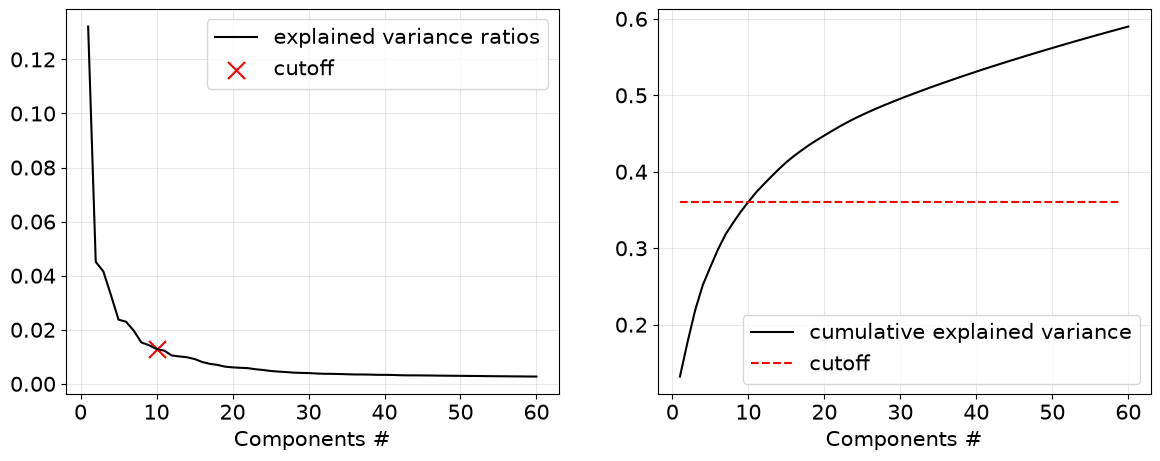

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ratios = pca.explained_variance_ratio_
cumulative_ratios = np.cumsum(ratios)
print(f"Variance explained by the {nb_keep} kept components: {100 * cumulative_ratios[nb_keep - 1]:.1f} %")

ax[0].plot(np.arange(1, len(ratios)+1), ratios, label='explained variance ratios', c='k')
ax[0].scatter([nb_keep], [ratios[nb_keep-1]], [150], marker='x', color='r', label='cutoff')
ax[1].plot(np.arange(1, len(cumulative_ratios)+1), cumulative_ratios, label='cumulative explained variance', c='k')
ax[1].hlines(y=cumulative_ratios[nb_keep-1], xmin=1, xmax=len(ratios)-1, linestyle='--', color='r', label='cutoff')

for k in range(2):
    ax[k].set_xlabel('Components #', size=15)
    ax[k].legend(prop={'size':15})
    ax[k].tick_params(axis='both', which='major', labelsize=15)

    ax[k].grid(True, alpha=0.3)
fig.savefig(op.join(FIG_DIR, "PCA_scree.png"), dpi=200, bbox_inches="tight")
plt.show()

## Loading maps of the 10 kept components (axial view) 

Save the loading maps

In [8]:
pca_clusters = []                                    
for k in range(nb_keep):
    vol = np.zeros(vol_shape, dtype=np.float32)
    vol[slice_non_background] = pca.components_[k]
    pca_clusters.append(vol)
    nib.save(nib.Nifti1Image(vol, affine), op.join(PCA_DIR, f"pca_loading_{k + 1:02d}.nii.gz"))   

Plot the loading maps in axial view

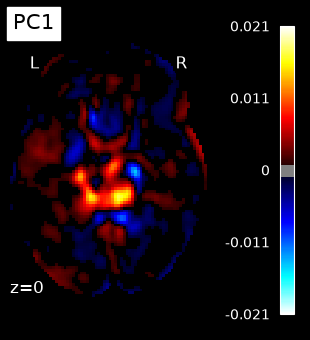

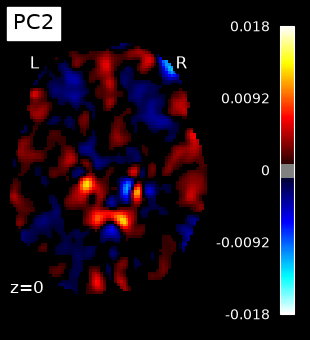

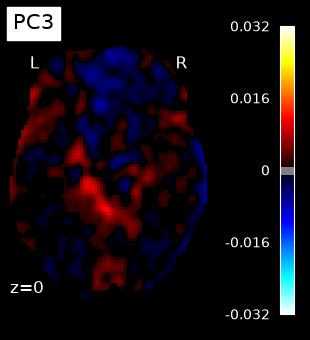

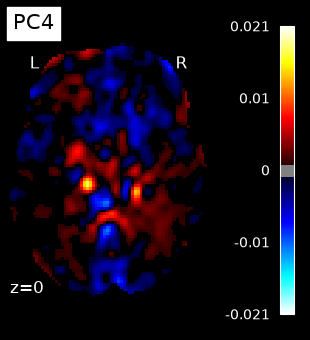

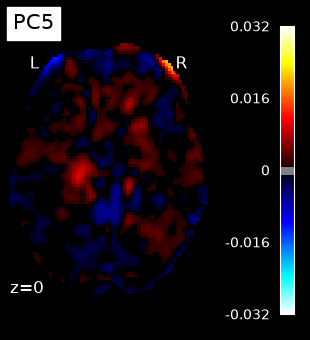

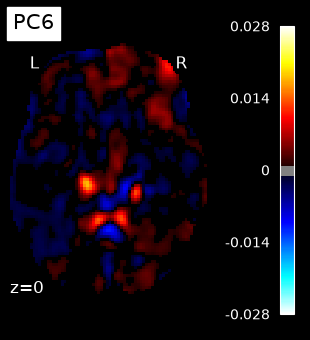

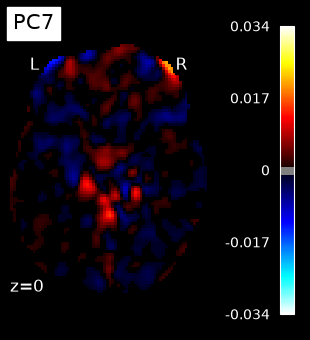

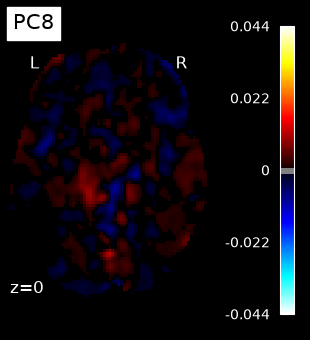

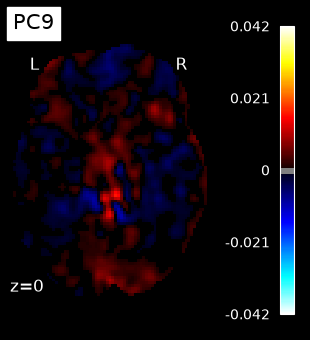

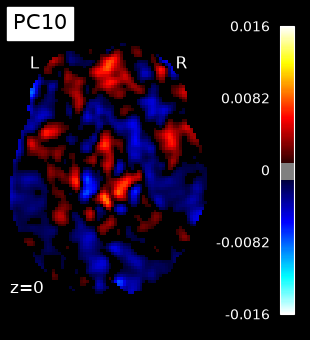

In [9]:
for i in range(10):
    visual_idx = i
    plot_stat_map(nib.Nifti1Image(pca_clusters[visual_idx], affine), bg_img=None, 
            threshold=1e-3, 
            display_mode = "z", cut_coords=[0], black_bg=True, 
            title=f'PC{visual_idx + 1}')

    plt.show()

In one single figure for the report 

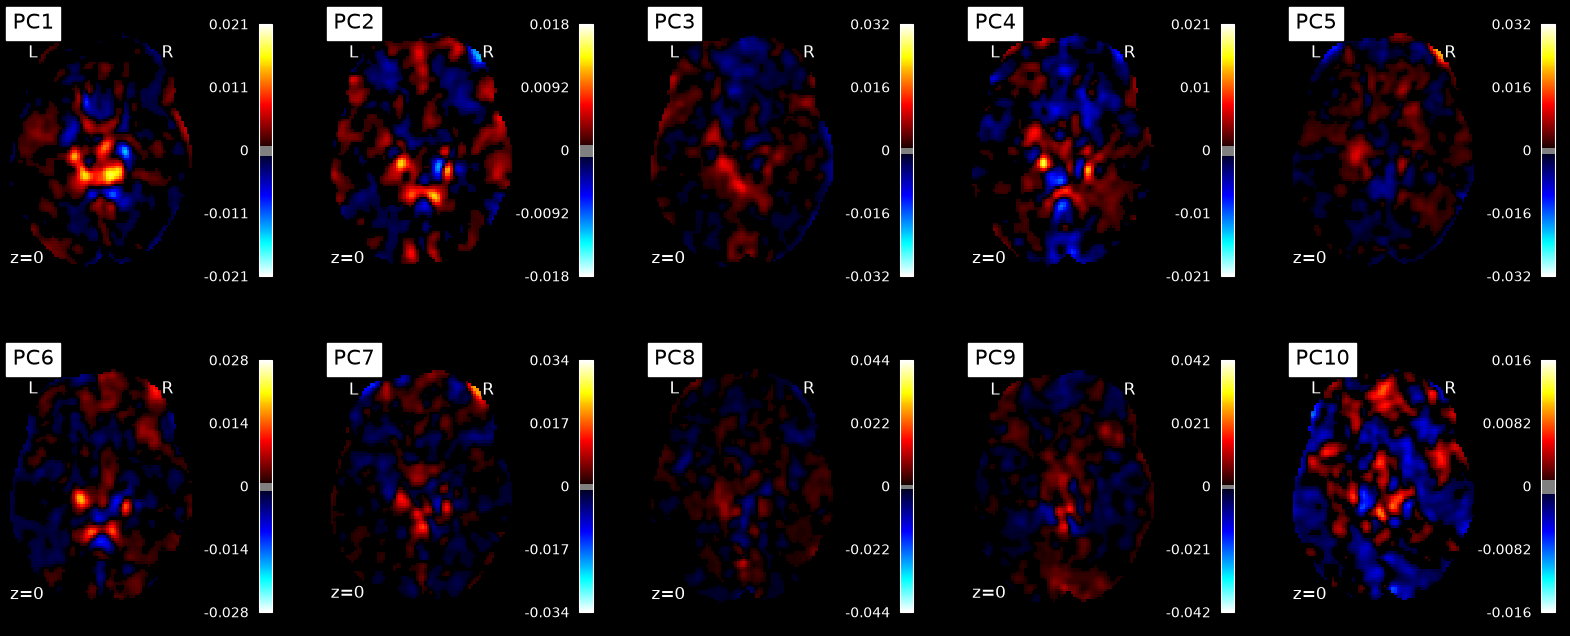

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8), facecolor="black")

for i, ax in enumerate(axes.ravel()):
    visual_idx = i
    plot_stat_map(nib.Nifti1Image(pca_clusters[visual_idx], affine), bg_img=None,
                  threshold=1e-3, 
                  display_mode="z", cut_coords=[0], black_bg=True, axes=ax,
                  title=f'PC{visual_idx + 1}')

fig.savefig(op.join(FIG_DIR, "PCA_loadings_overview.png"), dpi=200,
            bbox_inches="tight", facecolor="black")
plt.show()

## Correlation between the first 10 PC scores and the GLM regressors

In [11]:
dm_path = op.join(RESULTS_DIR, "design_matrix.csv")
design_matrix = pd.read_csv(dm_path, index_col=0)

reg = design_matrix.drop(columns=["constant"])
print("regressors:", reg.columns.tolist())

regressors: ['math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4']


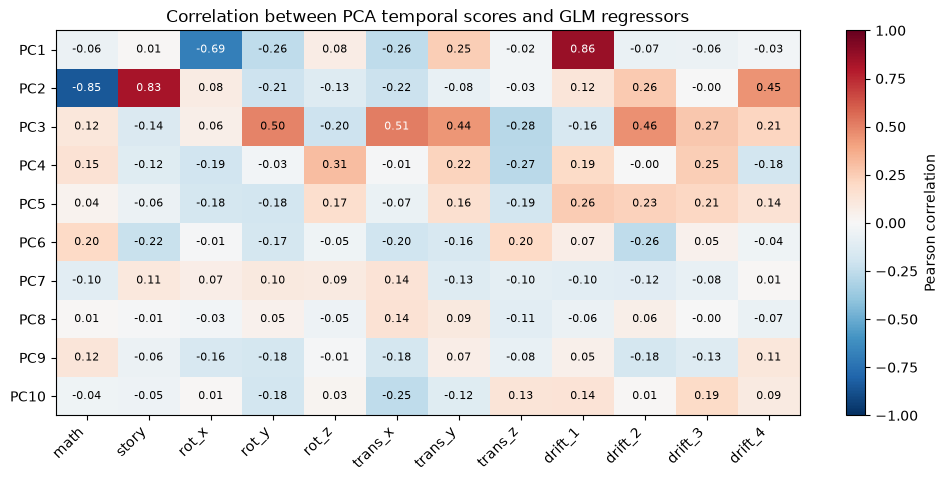

In [12]:
scores = pca.transform(X)[:, :10]
R = reg.to_numpy(dtype=float)

corr = np.corrcoef(scores.T, R.T)[:10, 10:]

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(R.shape[1]), reg.columns, rotation=45, ha="right")
ax.set_yticks(range(10), [f"PC{i + 1}" for i in range(10)])
for i in range(10):
    for j in range(R.shape[1]):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr[i, j]) > 0.5 else "black")
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation between PCA temporal scores and GLM regressors")
fig.savefig(op.join(FIG_DIR, "PCA_correlation_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()